# Appendix A — Data Reconstruction: Does the Gravity Model Reproduce US Aviation Flows?

**Built 2026-08-06** on top of the fused metapopulation model of notebook 08
(`src/fused_metapopulation.py`). The gravity kernel under test is the one the
model actually uses — the **PPML-calibrated kernel**
($W_{ij}^{\text{grav}} \propto N_j^{b_N}/d_{ij}^{b_d}$, $b_N \approx 1.0$,
$b_d \approx 0.55$).

**Experiment (one sentence).** From (i) 2020-Census populations, (ii)
jurisdiction distances and (iii) each state's *monthly outbound totals* we
reconstruct the full directional flow matrix $\hat F_{ij}(t)$, then measure
how well it reproduces the raw BTS T-100 flows $F_{ij}(t)$.

**What is calibrated vs what is predicted — the honest split:**

| Component | Input used | Status |
|---|---|---|
| $\mu_{0,i}$, $s_i(t)$ | observed per-state monthly **totals** | calibrated (exact by construction, §A.3) |
| directional shares $W_{ij}^{\text{grav}}$ | populations + distances only | **predicted** (the gravity hypothesis) |
| per-pair flows $\hat F_{ij}(t)$ | the two above | reconstruction (§A.5) |
| inbound totals $\hat I_j(t)$ | outbound calibration only | **predicted** (§A.7) |

The outbound *totals* carry no information about the gravity hypothesis —
they are matched by construction. Where the model stands or falls is the
**directional fingerprint**: shares, per-pair structure, top destinations,
inbound (which is not calibrated at all).

| Section | Test |
|---|---|
| §A.1 | data & calibration inputs |
| §A.2 | gravity kernel: PPML calibration ($b_N$, $b_d$) |
| §A.3 | [A] outbound-totals identity |
| §A.4 | [B] outbound directional shares (pooled / per-month / per-state) |
| §A.5 | [B2] per-pair reconstruction · [C] top destinations |
| §A.6 | [D] uniform temporal scaling |
| §A.7 | [E] inbound cross-sectional · [F] inbound time series |
| §A.8 | [H] robustness: contiguous-49 subset |
| §A.9 | [I] pair-level mobility: the saturated limit |
| §A.10 | reconstruction summary & limitations |

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

sys.path.insert(0, '../src')
from fused_metapopulation import (
    JURISDICTIONS, CENSUS_POPULATIONS, CONTIGUOUS, CODE_TO_NAME,
    T_MO, build_distance_matrix, build_gravity_kernel, fit_gravity_exponents,
    calibrate_mobility, build_month_index,
)
from data_loader import load_bts_state_pairs

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150})
ASSETS = '../assets'

def pear(x, y):
    if len(x) == 0 or np.std(x) == 0 or np.std(y) == 0:
        return np.nan
    return pearsonr(x, y)[0]

def spear(x, y):
    if len(x) == 0 or np.std(x) == 0 or np.std(y) == 0:
        return np.nan
    return spearmanr(x, y)[0]

def show_fig(path):
    from IPython.display import Image, display
    display(Image(filename=path))

print('ready | nodes:', len(JURISDICTIONS))

ready | nodes: 56


## §A.1 Data & calibration inputs

Raw source: BTS T-100 Market (US carriers, domestic markets), aggregated to
jurisdiction pairs by `data/bts_state_pairs_monthly.csv` — **63,721 rows**,
directional monthly passengers for every (origin, dest) among the 56 NYT/BTS
jurisdictions, 2020-01 → 2023-03 (39 months). Missing rows = zero passengers.

`calibrate_mobility()` builds the inter-state tensor $F_{ij}(t)$
(56×56×39), **excluding intra-state self-pairs** (they never leave the
patch), then per state:

$$\mu_{0,i} = \frac{\sum_{j\ne i} F_{ij}(\text{Jan-2020})}{T_{\text{mo}}},
\qquad
s_i(t) = \frac{\sum_{j\ne i} F_{ij}(t)}{\sum_{j\ne i} F_{ij}(\text{Jan-2020})},
\qquad T_{\text{mo}} = 30.44\ \text{d}$$

States with no Jan-2020 outbound flow at all ($\mu_{0,i}=0$) are kept but
decoupled (no outbound mobility) — **never extrapolated**.

In [2]:
states = list(JURISDICTIONS)
n = len(states)
months = build_month_index()
T = len(months)
Npop = np.array([CENSUS_POPULATIONS[s] for s in states], dtype=float)

mu0, s, months, F = calibrate_mobility(states, data_dir='../data')
out = F.sum(axis=1)               # (n, T) inter-state outbound / month
out0 = out[:, 0]
active = out0 > 0
inactive = [states[i] for i in np.where(~active)[0]]

pairs = load_bts_state_pairs('../data')
print(f'jurisdictions: {n} | months: {T} ({months[0][0]:04d}-{months[0][1]:02d} '
      f'.. {months[-1][0]:04d}-{months[-1][1]:02d}) | F tensor: {F.shape}')
print(f'raw rows: {len(pairs):,} | years {pairs.YEAR.min()}..{pairs.YEAR.max()}')
print(f'model-active origins (Jan-2020 inter-state outbound > 0): '
      f'{int(active.sum())}/{n}' + (f' | inactive: {inactive}' if inactive else ''))

# intra-state share of Jan-2020 outbound (data note: why self-flows are excluded)
Ff = np.zeros((n, n, T))
sidx = {s: i for i, s in enumerate(states)}
mkey = {(y, m): t for t, (y, m) in enumerate(months)}
for rr in pairs.itertuples(index=False):
    o, d = rr.origin_state, rr.dest_state
    if o not in sidx or d not in sidx:
        continue
    t = mkey.get((int(rr.YEAR), int(rr.MONTH)))
    if t is not None:
        Ff[sidx[o], sidx[d], t] += rr.PASSENGERS
intra_jan = np.diag(Ff[:, :, 0]) / np.maximum(Ff[:, :, 0].sum(axis=1), 1)
print('intra-state share of Jan-2020 outbound: median %.1f%% | max %.1f%% (%s) '
      '-> excluded from mu0/s' % (np.median(intra_jan) * 100, intra_jan.max() * 100,
                                  CODE_TO_NAME[states[int(np.argmax(intra_jan))]]))
print('Jan-2020 outbound (inter-state), top 5:')
for i in np.argsort(mu0)[::-1][:5]:
    print(f'  {CODE_TO_NAME[states[i]]:<24} {out0[i]:12,.0f} pax/month')

jurisdictions: 56 | months: 39 (2020-01 .. 2023-03) | F tensor: (56, 56, 39)
raw rows: 63,721 | years 2020..2023
model-active origins (Jan-2020 inter-state outbound > 0): 55/56 | inactive: ['DE']
intra-state share of Jan-2020 outbound: median 0.3% | max 65.5% (Northern Mariana Islands) -> excluded from mu0/s
Jan-2020 outbound (inter-state), top 5:
  Florida                     6,669,591 pax/month
  California                  5,513,926 pax/month
  Texas                       4,937,212 pax/month
  Georgia                     3,550,349 pax/month
  Illinois                    3,000,674 pax/month


## §A.2 Gravity kernel — PPML calibration

The directional shares come from **one kernel** (row-normalised,
$\sum_j W_{ij}^{\text{grav}} = 1$):

$$W_{ij}^{\text{grav}} \propto \frac{N_j^{b_N}}{d_{ij}^{b_d}}$$

i.e. a destination-population term and a distance-decay term only (the
origin term $N_i^\eta$ is kept in the code for kernel symmetry but cancels
under row normalisation). The exponents are fitted from the full 39-month
BTS panel via **PPML** — Poisson pseudo-maximum-likelihood (Santos Silva &
Tenreyro 2006):

$$F_{ijt} \sim \text{Poisson}\Big(\exp\big(\alpha_i + \gamma_t
+ b_N \ln N_j + b_d \ln d_{ij}\big)\Big)$$

with origin ($\alpha_i$) and month ($\gamma_t$) fixed effects. PPML is the
standard gravity estimator: consistent under multiplicative
heteroskedasticity, well-behaved with zero flows, and it avoids the Jensen
bias of log-linearising the model before estimating (the reason a
log-log OLS fit is not used for the kernel exponents).

In [3]:
D = build_distance_matrix(states)
r_ppml = fit_gravity_exponents(F, D, Npop, method='ppml')
print('PPML: b_d = %+.3f | b_N = %+.3f | deviance R2 = %.3f | converged = %s'
      % (r_ppml['b_d'], r_ppml['b_N'], r_ppml['r2'], r_ppml['converged']))
b_N, b_d = r_ppml['b_N'], -r_ppml['b_d']   # positive distance exponent

W = build_gravity_kernel(states, b_N=b_N, b_d=b_d)
print(f'kernel: W_ij ~ N_j^{b_N:.3f} / d_ij^{b_d:.3f}  '
      f'(row-normalised, d_min = 100 km, self-pairs = 0)')

PPML: b_d = -0.546 | b_N = +1.003 | deviance R2 = 0.698 | converged = True
kernel: W_ij ~ N_j^1.003 / d_ij^0.546  (row-normalised, d_min = 100 km, self-pairs = 0)


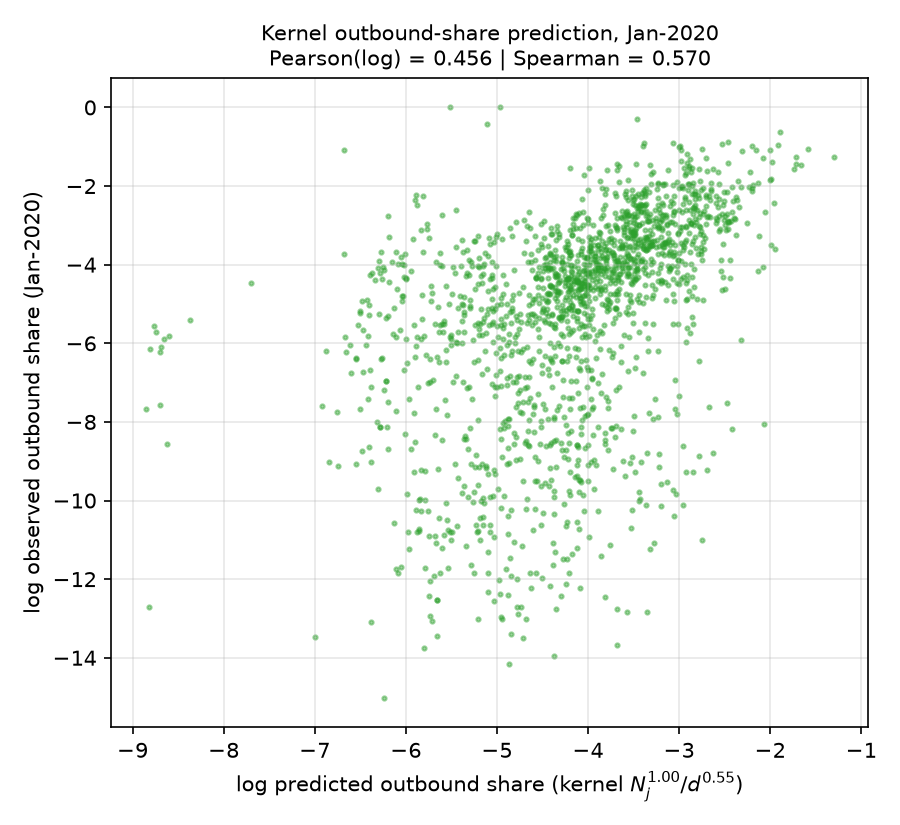

In [4]:
fig, ax = plt.subplots(figsize=(6, 5.5))
x, y = [], []
for i in np.where(active)[0]:
    o = F[i, :, 0]
    x += list(W[i]); y += list(o / o.sum())
x, y = np.array(x), np.array(y)
m = (x > 0) & (y > 0)
ax.scatter(np.log(x[m]), np.log(y[m]), s=4, alpha=0.45, color='C2')
ax.set_title(f'Kernel outbound-share prediction, Jan-2020\n'
             f'Pearson(log) = {pear(np.log(x[m]), np.log(y[m])):.3f} | '
             f'Spearman = {spear(np.log(x[m]), np.log(y[m])):.3f}', fontsize=10)
ax.set_xlabel('log predicted outbound share (kernel $N_j^{%.2f}/d^{%.2f}$)' % (b_N, b_d))
ax.set_ylabel('log observed outbound share (Jan-2020)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{ASSETS}/fig68_appA_kernel_shares.png'); plt.show()
show_fig(f'{ASSETS}/fig68_appA_kernel_shares.png')

## §A.3 [A] Outbound-totals identity (calibration exactness)

Sanity check first: with $\hat F_{ij}(t) = s_i(t)\,\mu_{0,i}\,W_{ij}^{\text{grav}}\,T_{\text{mo}}$,
each state's predicted **total** outbound equals its observed total **by
construction** (whatever the kernel). The reconstruction experiment therefore
rests entirely on the directional tests that follow.

In [5]:
pred_month = s * mu0[:, None] * T_MO
err = np.abs(pred_month - out)
print('max |pred - obs| over active states: %.3e pax/month (relative %.2e)'
      % (err[active].max(), np.max(err[active] / np.maximum(out[active], 1))))
for i in np.where(~active)[0]:
    nz = (out[i] > 0).sum()
    print(f'{states[i]} (mu0=0, no extrapolation): model outbound = 0; '
          f'data has {nz}/{T} nonzero months (max {out[i].max():,.0f} pax/mo) '
          f'-> excluded below')

max |pred - obs| over active states: 9.313e-10 pax/month (relative 2.60e-16)
DE (mu0=0, no extrapolation): model outbound = 0; data has 29/39 nonzero months (max 6,931 pax/mo) -> excluded below


## §A.4 [B] Outbound directional shares

The core test: does the gravity kernel reproduce **where** the outbound
passengers go? For each active origin $i$ and month $t$,
$\hat p_{ij} = W_{ij}^{\text{grav}}$ is compared with the observed share
$p_{ij}(t) = F_{ij}(t)/\sum_j F_{ij}(t)$ across all 56 destinations.

In [6]:
def pooled_shares(month=None):
    x, y, lx, ly = [], [], [], []
    tsel = range(T) if month is None else [months.index(month)]
    for i in np.where(active)[0]:
        for t in tsel:
            o = F[i, :, t]; tot = o.sum()
            if tot <= 0:
                continue
            phat = o / tot
            x += list(W[i]); y += list(phat)
            m = phat > 0
            if m.sum() >= 2:
                lx += list(np.log(phat[m])); ly += list(np.log(W[i][m]))
    return np.array(x), np.array(y), np.array(lx), np.array(ly)

x, y, lx, ly = pooled_shares()
print(f'pooled (all active state·month·dest, N={len(x):,}):')
print(f'  Pearson(raw)  = {pear(x, y):.4f}')
print(f'  Spearman      = {spear(x, y):.4f}')
print(f'  Pearson(log)  = {pear(lx, ly):.4f}   (only observed dests, N={len(lx):,})')
x0, y0, lx0, ly0 = pooled_shares(month=(2020, 1))
print(f'Jan-2020 only:  Pearson(raw) = {pear(x0, y0):.4f} | Spearman = '
      f'{spear(x0, y0):.4f} | Pearson(log) = {pear(lx0, ly0):.4f}')
share_summary = pd.DataFrame([{'kernel': f'N_j^{b_N:.2f}/d^{b_d:.2f}',
                               'P_pooled': pear(x, y), 'S_pooled': spear(x, y),
                               'P_jan': pear(x0, y0), 'S_jan': spear(x0, y0)}])

pooled (all active state·month·dest, N=119,784):
  Pearson(raw)  = 0.4484
  Spearman      = 0.5789
  Pearson(log)  = 0.4543   (only observed dests, N=62,066)
Jan-2020 only:  Pearson(raw) = 0.4656 | Spearman = 0.5917 | Pearson(log) = 0.4592


In [7]:
# per-month pooled correlation
mm_p, mm_s = [], []
for t in range(T):
    a, b = [], []
    for i in np.where(active)[0]:
        o = F[i, :, t]; tot = o.sum()
        if tot <= 0:
            continue
        a += list(o / tot); b += list(W[i])
    mm_p.append(pear(np.array(a), np.array(b)))
    mm_s.append(spear(np.array(a), np.array(b)))
print('monthly pooled share correlation (calibrated kernel):')
print(f'{"month":>7} | {"Pearson":>7} | {"Spearman":>8}')
for t in [0, 3, 6, 11, 23, 35, 38]:
    y, m = months[t]
    print(f'{y}-{m:02d} | {mm_p[t]:7.3f} | {mm_s[t]:8.3f}')
print(f'median Pearson {np.median(mm_p):.3f} (range {np.min(mm_p):.3f}..{np.max(mm_p):.3f})')

monthly pooled share correlation (calibrated kernel):
  month | Pearson | Spearman
2020-01 |   0.466 |    0.592
2020-04 |   0.416 |    0.548
2020-07 |   0.436 |    0.546
2020-12 |   0.456 |    0.579
2021-12 |   0.456 |    0.587
2022-12 |   0.462 |    0.581
2023-03 |   0.458 |    0.586
median Pearson 0.452 (range 0.416..0.473)


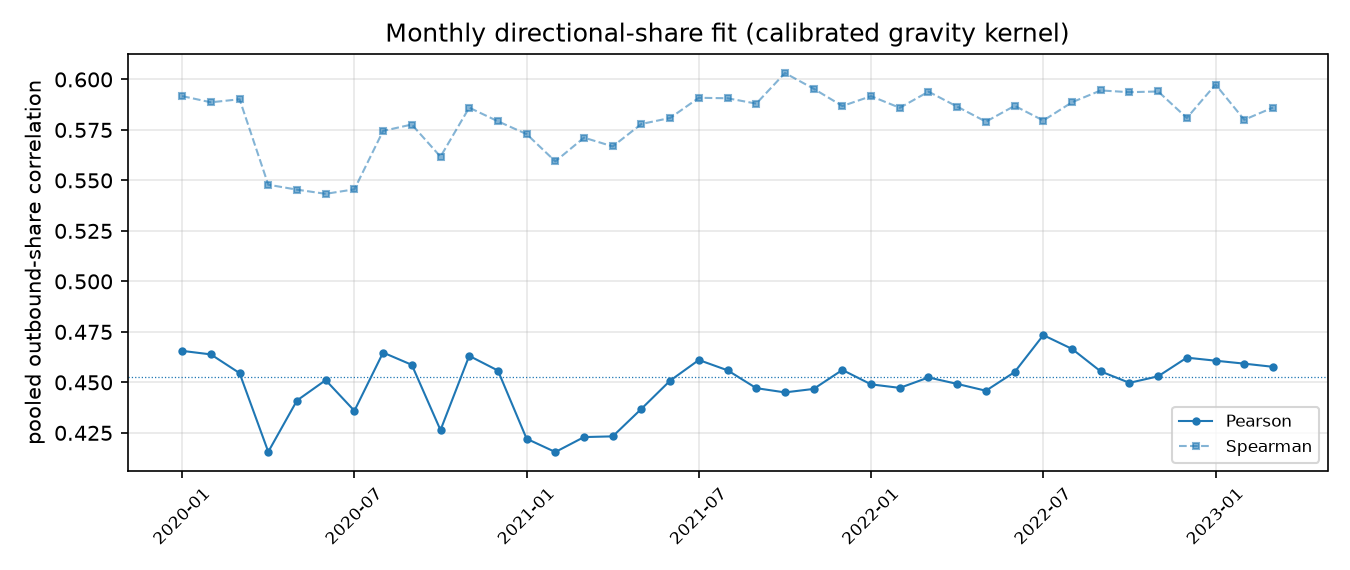

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(T), mm_p, 'o-', ms=3, lw=1, color='C0', label='Pearson')
ax.plot(range(T), mm_s, 's--', ms=3, lw=1, color='C0', alpha=0.55, label='Spearman')
ax.axhline(np.median(mm_p), color='C0', lw=0.6, ls=':')
ax.set_xticks(range(0, T, 6))
ax.set_xticklabels([f'{y}-{m:02d}' for y, m in months[::6]], rotation=45, fontsize=8)
ax.set_ylabel('pooled outbound-share correlation')
ax.set_title('Monthly directional-share fit (calibrated gravity kernel)')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{ASSETS}/fig70_appA_share_corr_monthly.png'); plt.show()
show_fig(f'{ASSETS}/fig70_appA_share_corr_monthly.png')

In [9]:
# per-state median Pearson (calibrated)
med = []
for i in np.where(active)[0]:
    ps = []
    for t in range(T):
        o = F[i, :, t]; tot = o.sum()
        if tot <= 0:
            continue
        rv = pear(o / tot, W[i])
        if not np.isnan(rv):
            ps.append(rv)
    if ps:
        med.append((states[i], np.median(ps), np.min(ps), np.max(ps), len(ps)))
med_v = np.array([r[1] for r in med])
print('per-state median Pearson (calibrated): median %.3f | IQR [%.3f, %.3f] | '
      'range [%.3f, %.3f]' % (np.median(med_v),
                              np.percentile(med_v, 25), np.percentile(med_v, 75),
                              med_v.min(), med_v.max()))
worst = sorted(med, key=lambda t: t[1])[:3]
best = sorted(med, key=lambda t: -t[1])[:3]
print('  worst 3:', [(CODE_TO_NAME[s], round(v, 3)) for s, v, _, _, _ in worst])
print('  best  3:', [(CODE_TO_NAME[s], round(v, 3)) for s, v, _, _, _ in best])

ps_df = pd.DataFrame(
    [{'state': s, 'name': CODE_TO_NAME[s], 'months_used': mu,
      'medPearson_cal': v, 'minPearson_cal': mn, 'maxPearson_cal': mx}
     for s, v, mn, mx, mu in med])
ps_df = ps_df.sort_values('medPearson_cal', ascending=False).reset_index(drop=True)
ps_df.to_csv('../scripts/appendixA_state_corr.csv', index=False)
print('per-state table saved -> scripts/appendixA_state_corr.csv')

per-state median Pearson (calibrated): median 0.597 | IQR [0.492, 0.777] | range [-0.097, 0.949]
  worst 3: [('Guam', np.float64(-0.097)), ('Northern Mariana Islands', np.float64(-0.084)), ('American Samoa', np.float64(-0.065))]
  best  3: [('Nevada', np.float64(0.949)), ('Colorado', np.float64(0.941)), ('Arizona', np.float64(0.927))]


per-state table saved -> scripts/appendixA_state_corr.csv


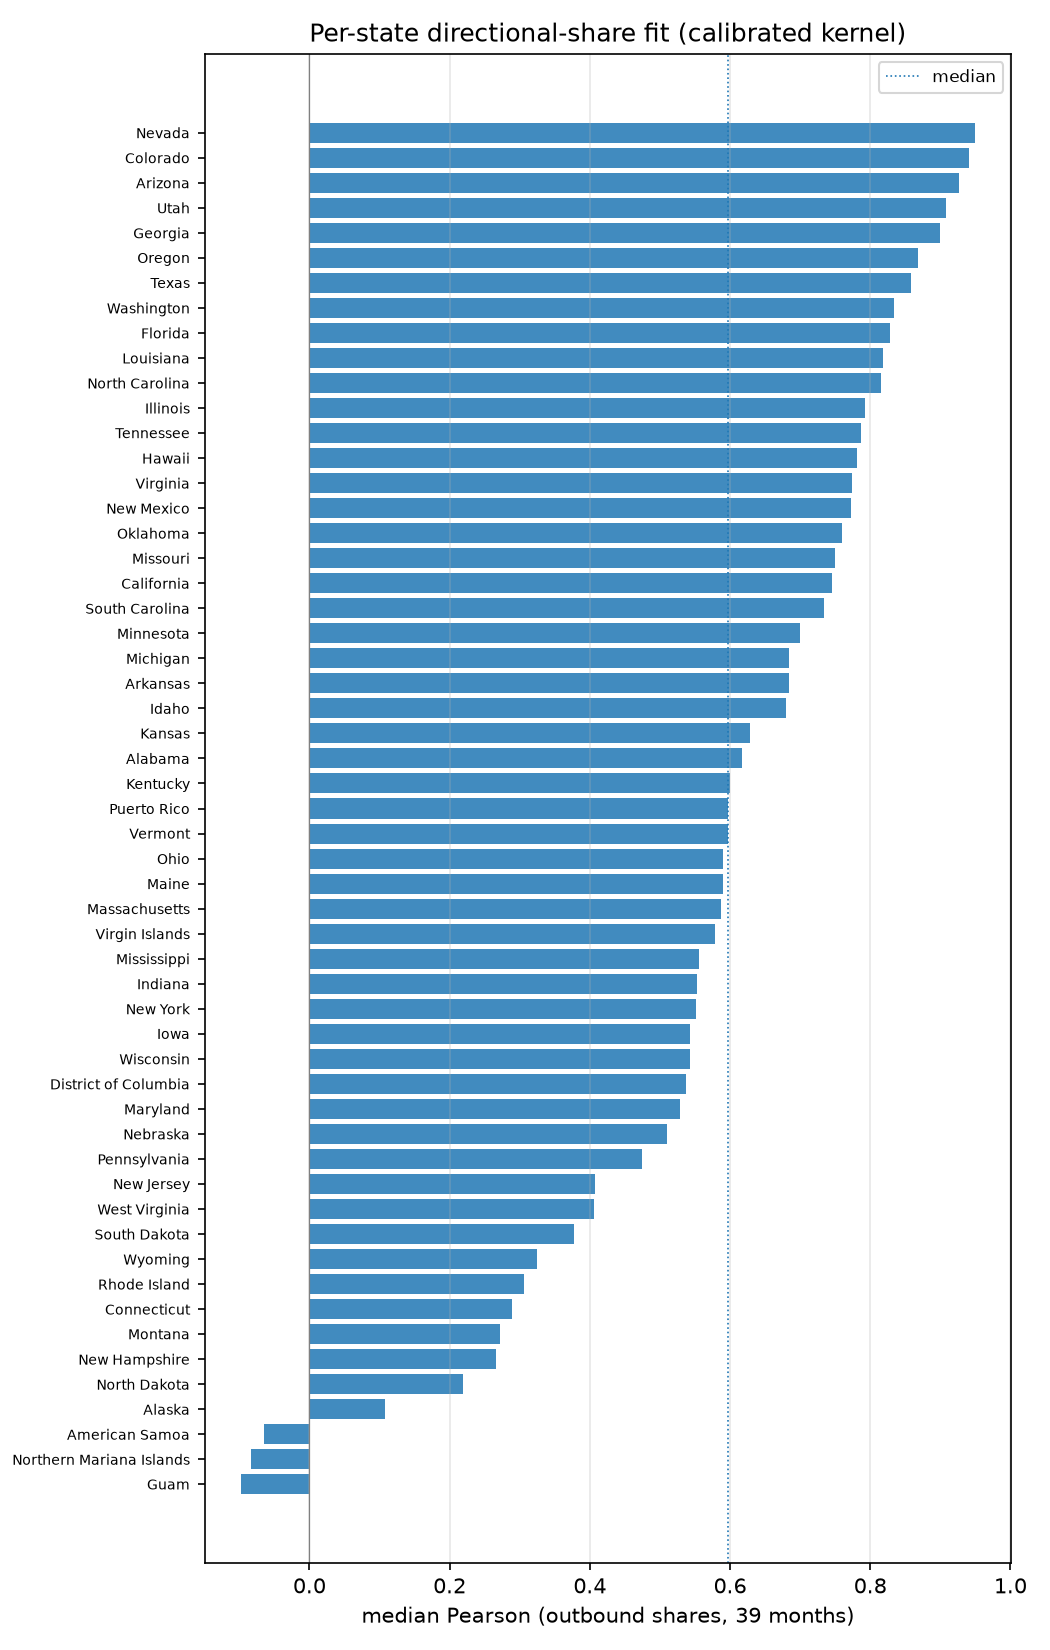

In [10]:
order = np.argsort(med_v)
fig, ax = plt.subplots(figsize=(7, 11))
ypos = np.arange(len(order))
ax.barh(ypos, med_v[order], height=0.8, color='C0', alpha=0.85)
ax.set_yticks(ypos)
ax.set_yticklabels([CODE_TO_NAME[med[i][0]] for i in order], fontsize=6.5)
ax.axvline(0, color='grey', lw=0.6)
ax.axvline(np.median(med_v), color='C0', lw=0.8, ls=':', label='median')
ax.set_xlabel('median Pearson (outbound shares, 39 months)')
ax.set_title('Per-state directional-share fit (calibrated kernel)')
ax.legend(fontsize=8); ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{ASSETS}/fig71_appA_state_corr.png'); plt.show()
show_fig(f'{ASSETS}/fig71_appA_state_corr.png')

## §A.5 [B2] Per-pair reconstruction · [C] Top destinations

**Reconstruction.** The full predicted tensor
$\hat F_{ij}(t) = s_i(t)\,\mu_{0,i}\,W_{ij}^{\text{grav}}\,T_{\text{mo}}$
(pax/month) vs the observed $F_{ij}(t)$, pooled over all nonzero pairs —
the literal "data restoration" test of the gravity model.

**Top destinations.** Per active state-month, does the kernel name the same
largest destination(s) as the data?

In [11]:
pred = (s[:, None, :] * mu0[:, None, None] * W[:, :, None] * T_MO)
m2 = F > 0
a = pred[m2]; b = F[m2]
lg = (a > 0) & (b > 0)
logy = np.log(b[lg]); logp = np.log(a[lg])
r2log = 1 - np.sum((logy - logp) ** 2) / np.sum((logy - logy.mean()) ** 2)
fac = a[lg] / b[lg]
print(f'nonzero pairs (i,j,t): {m2.sum():,}')
print(f'Pearson(raw) = {pear(a, b):.4f} | Spearman = {spear(a, b):.4f}')
print(f'Pearson(log-log) = {pear(logp, logy):.4f} | Spearman(log-log) = {spear(logp, logy):.4f}')
print(f'R2 (log-log) = {r2log:.3f} | median |log2(pred/obs)| = {np.median(np.abs(np.log2(fac))):.3f} '
      f'(median factor error = {2 ** np.median(np.abs(np.log2(fac))):.2f}x)')

nonzero pairs (i,j,t): 62,224
Pearson(raw) = 0.8200 | Spearman = 0.6949
Pearson(log-log) = 0.6001 | Spearman(log-log) = 0.6941
R2 (log-log) = 0.247 | median |log2(pred/obs)| = 1.381 (median factor error = 2.60x)


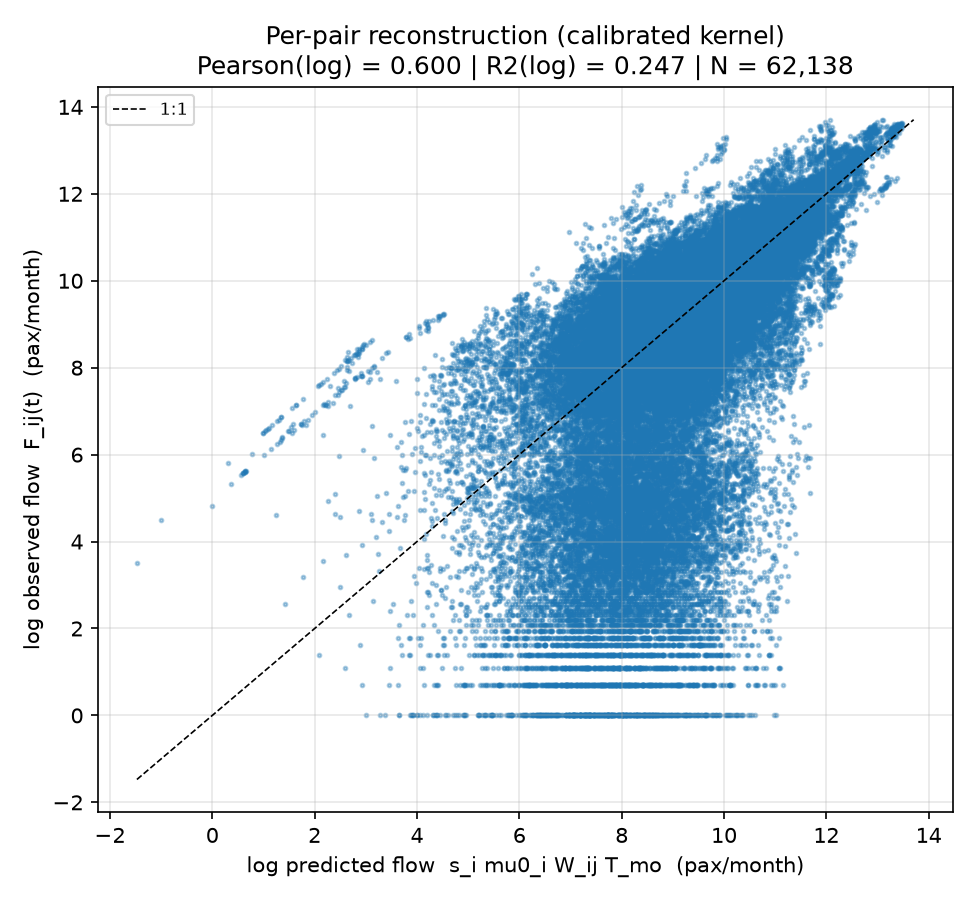

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(logp, logy, s=3, alpha=0.35, color='C0')
lo, hi = min(logp.min(), logy.min()), max(logp.max(), logy.max())
ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8, label='1:1')
ax.set_xlabel('log predicted flow  s_i mu0_i W_ij T_mo  (pax/month)')
ax.set_ylabel('log observed flow  F_ij(t)  (pax/month)')
ax.set_title(f'Per-pair reconstruction (calibrated kernel)\n'
             f'Pearson(log) = {pear(logp, logy):.3f} | R2(log) = {r2log:.3f} | N = {len(logp):,}')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{ASSETS}/fig69_appA_pair_reconstruction.png'); plt.show()
show_fig(f'{ASSETS}/fig69_appA_pair_reconstruction.png')

In [13]:
h1, h3 = [], []
for i in np.where(active)[0]:
    for t in range(T):
        o = F[i, :, t]
        if o.sum() <= 0:
            continue
        h1.append(np.argmax(o) == np.argmax(W[i]))
        s3o = set(np.argsort(o)[-3:]); s3g = set(np.argsort(W[i])[-3:])
        h3.append(len(s3o & s3g) / 3)
print(f'state-months with traffic: {len(h1):,}')
print(f'top-1 destination match  : {np.mean(h1) * 100:.1f}% ({np.sum(h1)}/{len(h1)})')
print(f'top-3 destination overlap: {np.mean(h3) * 100:.1f}%')

state-months with traffic: 2,139
top-1 destination match  : 34.5% (737/2139)
top-3 destination overlap: 34.8%


## §A.6 [D] Uniform temporal scaling

The model's time dependence is a **uniform multiplicative scale per
origin-month**: every pair $i\!\to\!j$ scales by the same $s_i(t)$. If that
holds, pair-level relative flows $\frac{F_{ij}(t)}{F_{ij}(\text{Jan-2020})}$
should track $s_i(t)$ with pooled slope 1.00. This tests the *temporal* half
of the model (independent of the kernel).

In [14]:
rs_d, Xd, Yd = [], [], []
for i in np.where(active)[0]:
    for j in range(n):
        if i == j or F[i, j, 0] <= 0:
            continue
        x = F[i, j, :] / F[i, j, 0]
        m = (x > 0) & (s[i] > 0)
        if m.sum() < 5:
            continue
        rv = pear(x[m], s[i][m])
        if not np.isnan(rv):
            rs_d.append(rv)
        Xd.append(np.log(s[i][m])); Yd.append(np.log(x[m]))
Xd = np.concatenate(Xd); Yd = np.concatenate(Yd)
bfit, bres = np.polyfit(Xd, Yd, 1)
r2d = 1 - np.sum((Yd - np.polyval([bfit, bres], Xd)) ** 2) / np.sum((Yd - Yd.mean()) ** 2)
rs_d = np.array(rs_d)
print(f'origin-dest pairs used: {len(rs_d):,} (Jan flow > 0, >= 5 nonzero months)')
print(f'pair correlation: median {np.median(rs_d):.3f} | IQR '
      f'[{np.percentile(rs_d, 25):.3f}, {np.percentile(rs_d, 75):.3f}] | '
      f'frac > 0.5: {np.mean(rs_d > 0.5) * 100:.1f}% | frac > 0.8: {np.mean(rs_d > 0.8) * 100:.1f}%')
print(f'pooled regression log(F_ij/F_jan) = {bfit:.3f} * log(s_i) + {bres:.3f} '
      f'(expect slope 1.00) | R2 = {r2d:.3f} | N = {len(Xd):,}')

origin-dest pairs used: 1,677 (Jan flow > 0, >= 5 nonzero months)
pair correlation: median 0.874 | IQR [0.539, 0.949] | frac > 0.5: 77.0% | frac > 0.8: 59.5%
pooled regression log(F_ij/F_jan) = 1.145 * log(s_i) + 0.034 (expect slope 1.00) | R2 = 0.299 | N = 56,915


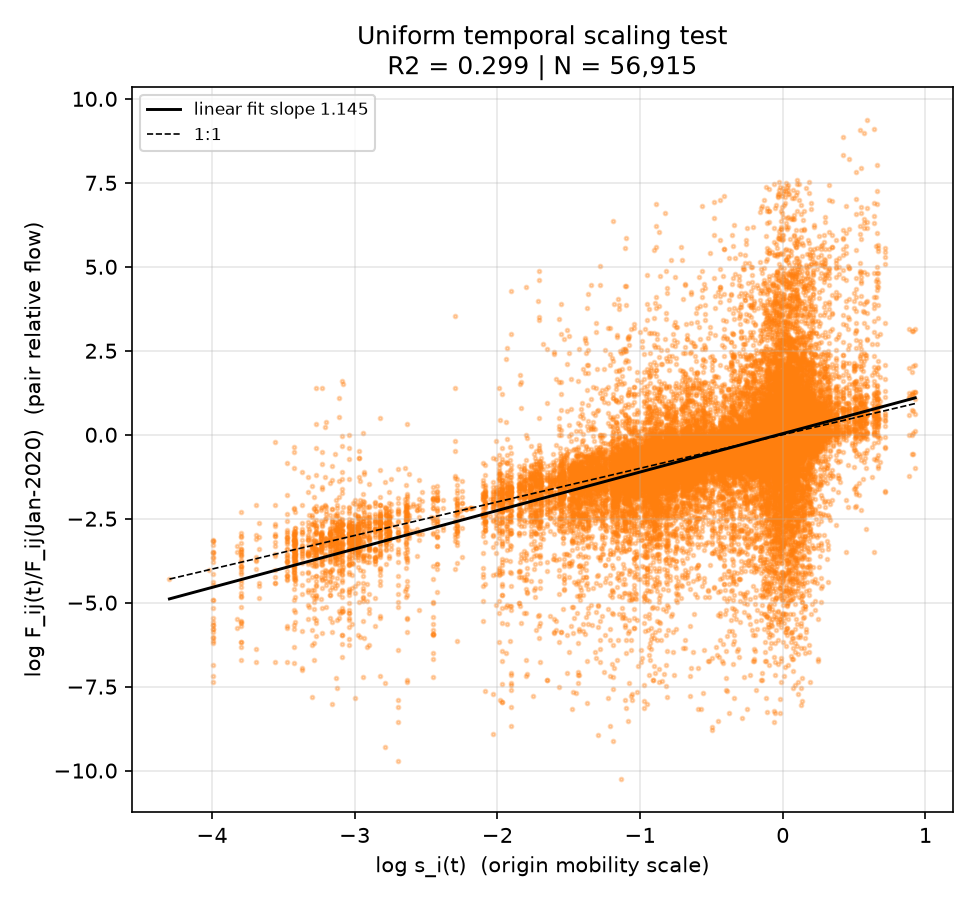

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(Xd, Yd, s=3, alpha=0.3, color='C1')
xs = np.linspace(Xd.min(), Xd.max(), 50)
ax.plot(xs, bfit * xs + bres, 'k-', lw=1.4, label=f'linear fit slope {bfit:.3f}')
ax.plot(xs, xs, 'k--', lw=0.8, label='1:1')
ax.set_xlabel('log s_i(t)  (origin mobility scale)')
ax.set_ylabel('log F_ij(t)/F_ij(Jan-2020)  (pair relative flow)')
ax.set_title(f'Uniform temporal scaling test\nR2 = {r2d:.3f} | N = {len(Xd):,}')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{ASSETS}/fig72_appA_temporal_scaling.png'); plt.show()
show_fig(f'{ASSETS}/fig72_appA_temporal_scaling.png')

## §A.7 [E]·[F] Inbound totals — *uncalibrated* prediction

Inbound is never calibrated: $\hat I_j(t) = \sum_i s_i(t)\mu_{0,i}W_{ij}T_{\text{mo}}$
uses only the **outbound** calibration. Two views:

- **[E] cross-sectional** — per month, predicted vs observed inbound across
  the 56 destinations (does gravity rank the hubs correctly?);
- **[F] time series** — per destination, the 39-month curve (shares the
  national COVID trend, so expect high correlations).

In [16]:
pred_in = W.T @ (s * mu0[:, None]) * T_MO      # (n, T) pax/month in
obs_in = F.sum(axis=0)
r_cs = np.array([pear(pred_in[:, t], obs_in[:, t]) for t in range(T)])
r_cs = r_cs[~np.isnan(r_cs)]
print('[E] cross-sectional (per month, across %d dests): median %.3f | IQR '
      '[%.3f, %.3f] | min %.3f | max %.3f | frac > 0.7: %.0f%%'
      % (n, np.median(r_cs), np.percentile(r_cs, 25), np.percentile(r_cs, 75),
         r_cs.min(), r_cs.max(), np.mean(r_cs > 0.7) * 100))
a = pred_in.ravel(); b = obs_in.ravel()
lg = b > 0
print('[E] pooled: Pearson = %.4f | Spearman = %.4f | Pearson(log) = %.4f'
      % (pear(a, b), spear(a, b), pear(np.log(a[lg]), np.log(b[lg]))))

r_ts = []
for j in range(n):
    if obs_in[j].sum() <= 0:
        continue
    rv = pear(pred_in[j], obs_in[j])
    if not np.isnan(rv):
        r_ts.append((states[j], rv))
rv_arr = np.array([v for _, v in r_ts])
print('[F] inbound time series: n = %d | median %.3f | IQR [%.3f, %.3f]'
      % (len(r_ts), np.median(rv_arr), np.percentile(rv_arr, 25), np.percentile(rv_arr, 75)))
r_sorted = sorted(r_ts, key=lambda t: t[1])
print('[F] worst 3:', [(CODE_TO_NAME[s], round(v, 3)) for s, v in r_sorted[:3]])
print('[F] best  3:', [(CODE_TO_NAME[s], round(v, 3)) for s, v in r_sorted[-3:]])

[E] cross-sectional (per month, across 56 dests): median 0.827 | IQR [0.803, 0.847] | min 0.720 | max 0.865 | frac > 0.7: 100%
[E] pooled: Pearson = 0.8457 | Spearman = 0.8395 | Pearson(log) = 0.8104
[F] inbound time series: n = 56 | median 0.982 | IQR [0.954, 0.988]
[F] worst 3: [('Delaware', np.float64(0.323)), ('American Samoa', np.float64(0.615)), ('Wyoming', np.float64(0.62))]
[F] best  3: [('Ohio', np.float64(0.994)), ('Nebraska', np.float64(0.995)), ('Georgia', np.float64(0.995))]


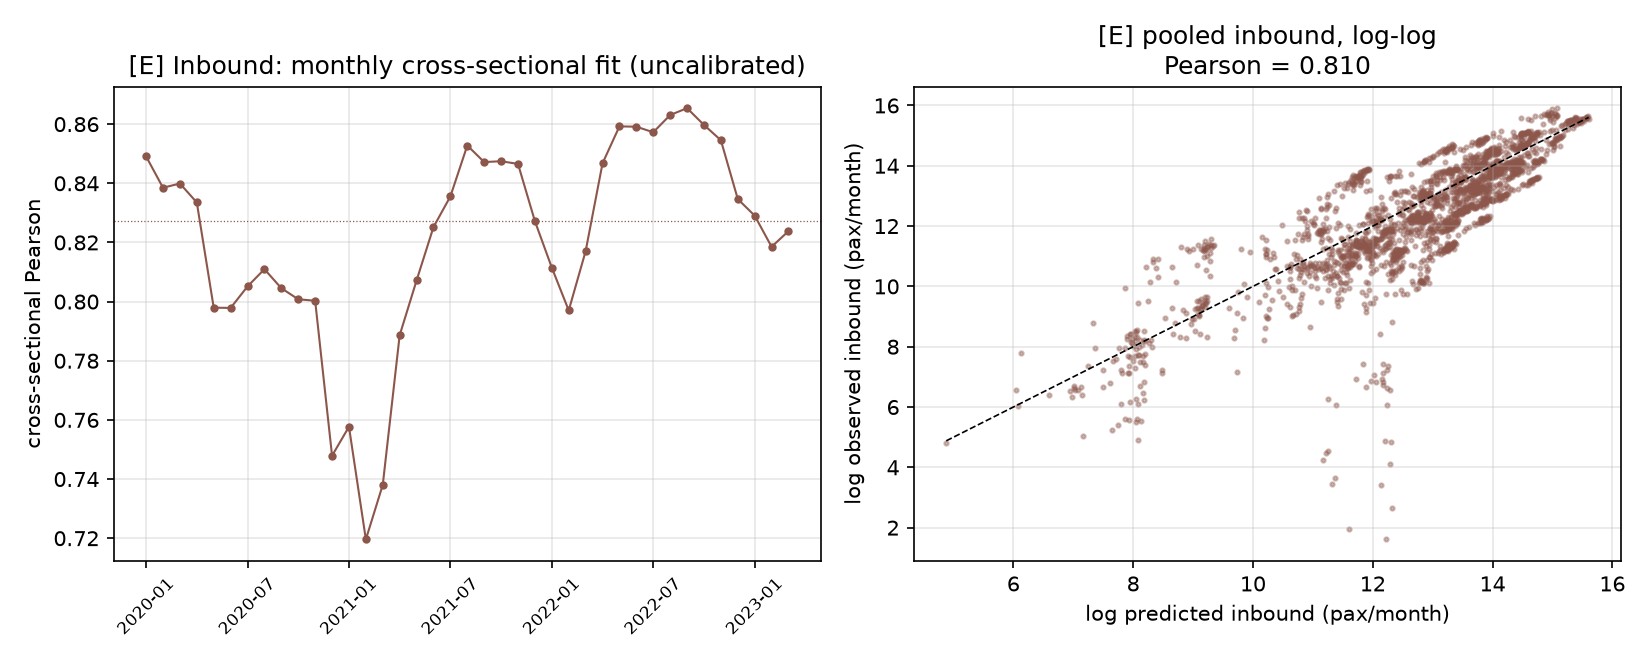

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].plot(range(T), r_cs, 'o-', ms=3, lw=1, color='C5')
axes[0].axhline(np.median(r_cs), color='C5', lw=0.6, ls=':')
axes[0].set_xticks(range(0, T, 6))
axes[0].set_xticklabels([f'{y}-{m:02d}' for y, m in months[::6]], rotation=45, fontsize=8)
axes[0].set_ylabel('cross-sectional Pearson')
axes[0].set_title('[E] Inbound: monthly cross-sectional fit (uncalibrated)')
axes[0].grid(alpha=0.3)
lg2 = obs_in.ravel() > 0
axes[1].scatter(np.log(pred_in.ravel()[lg2]), np.log(obs_in.ravel()[lg2]),
                s=4, alpha=0.4, color='C5')
lo = np.log(pred_in.ravel()[lg2]).min(); hi = np.log(pred_in.ravel()[lg2]).max()
axes[1].plot([lo, hi], [lo, hi], 'k--', lw=0.8)
axes[1].set_xlabel('log predicted inbound (pax/month)')
axes[1].set_ylabel('log observed inbound (pax/month)')
axes[1].set_title(f'[E] pooled inbound, log-log\nPearson = '
                  f'{pear(np.log(pred_in.ravel()[lg2]), np.log(obs_in.ravel()[lg2])):.3f}')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{ASSETS}/fig73_appA_inbound.png'); plt.show()
show_fig(f'{ASSETS}/fig73_appA_inbound.png')

## §A.8 [H] Robustness — contiguous 49 only

Re-run the directional-share test on the **contiguous 48 states + DC**
(excluding AK, HI and the five territories) to make sure results are not
driven by the small long-haul/territory markets. The kernel is rebuilt and
the PPML exponents refit on the subset.

In [18]:
idx = [states.index(c) for c in CONTIGUOUS]
r_ppml49 = fit_gravity_exponents(F[np.ix_(idx, idx, range(T))],
                                 D[np.ix_(idx, idx)], Npop[idx], method='ppml')
Wc = build_gravity_kernel(CONTIGUOUS, b_N=r_ppml49['b_N'], b_d=-r_ppml49['b_d'])
print(f'contiguous-49 PPML refit: b_N = {r_ppml49["b_N"]:.3f} | b_d = '
      f'{-r_ppml49["b_d"]:.3f} | deviance R2 = {r_ppml49["r2"]:.3f}')

def pooled_contig(Wk):
    x, y = [], []
    for ii, i in enumerate(idx):
        if not active[i]:
            continue
        for t in range(T):
            o = F[i, idx, t]; tot = o.sum()
            if tot <= 0:
                continue
            x += list(Wk[ii]); y += list(o / tot)
    return np.array(x), np.array(y)

a, b = pooled_contig(Wc)
print(f'contiguous-49 pooled: Pearson = {pear(a, b):.4f} | Spearman = '
      f'{spear(a, b):.4f} | N = {len(a):,}')
print('(full-56 reference: Pearson = 0.45, §A.4)')

contiguous-49 PPML refit: b_N = 1.063 | b_d = 0.574 | deviance R2 = 0.725
contiguous-49 pooled: Pearson = 0.5634 | Spearman = 0.5995 | N = 91,728
(full-56 reference: Pearson = 0.45, §A.4)


## §A.9 [I] Pair-level mobility — the *saturated* limit

"Give every pair its own μ and s" is the limit of this experiment:

$$W_{ij}(t) = \mu_{0,ij}\, s_{ij}(t),
\qquad
\mu_{0,ij} = \frac{F_{ij}(\text{Jan-2020})}{T_{\text{mo}}},
\qquad
s_{ij}(t) = \frac{F_{ij}(t)}{F_{ij}(\text{Jan-2020})}
\qquad
\Rightarrow \quad W_{ij}(t)\,T_{\text{mo}} = F_{ij}(t)
\ \text{exactly}$$

One parameter per observed data point — the model becomes a **replay of the
data** (pairs with no Jan-2020 baseline keep $s_{ij}\equiv 0$, same
no-extrapolation rule as state-level DE). For reference we also show the
middle ground: a **time-invariant pair factor** $\mu_{0,ij}$ (fitted as the
mean log residual of the gravity prediction) while keeping the shared
per-state temporal scaling $s_i(t)$.

| Mode | R²(log) | Parameters |
|---|---|---|
| gravity kernel + per-state $\mu_{0,i}, s_i(t)$ (§A.5) | 0.247 | ~200 |
| + time-invariant pair factor $\mu_{0,ij}$ (per-state $s_i(t)$) | 0.908 | +3,080 |
| full per-pair $\mu_{0,ij}\cdot s_{ij}(t)$ | 1.000 (by construction) | ~62,000 ≈ data points |

**Honest reading.** The saturated column is *not* a better model — it is the
data itself. The gravity model's value is that ~200 parameters predict the
directional structure from population + distance; the pair-level versions
memorise it. The interesting middle ground is the time-invariant pair factor
(0.25 → 0.91): it lets each corridor keep its own baseline weight while the
*temporal* evolution stays a per-state scale, so the model still generalises
to months not in the training window. The pair-level residual that the
saturated model absorbs is shown below — it is large (median ×2.6 miss) but
idiosyncratic, not explained by distance (corr ≈ 0).

In [19]:
from fused_metapopulation import calibrate_mobility as _cm

mu0_mat, s_tensor, months2, F2 = _cm(states, data_dir='../data', pair_level=True)
W_pair = mu0_mat[:, :, None] * s_tensor            # daily, n×n×T
base = F2[:, :, 0] > 0
print(f'pairs with a Jan-2020 baseline: {int(base.sum())}/{base.size}')
print(f'reconstruction exact on baseline pairs: '
      f'{np.allclose((W_pair * T_MO)[base], F2[base], atol=1e-6)}')
print(f'flow on non-baseline pairs (never coupled, same rule as DE): '
      f'{100 * F2[~base].sum() / F2.sum():.3f}% of total volume')

# middle ground: time-invariant pair factor on top of the gravity prediction
logF = np.log(np.maximum(F, 1e-12))
logP = np.log(np.maximum(pred, 1e-12))
mask = (F > 0) & (pred > 0) & active[:, None, None]
pair_res = np.zeros((n, n))
for i in np.where(active)[0]:
    for j in range(n):
        sel = mask[i, j, :]
        if sel.sum() > 0:
            pair_res[i, j] = np.mean(logF[i, j, sel] - logP[i, j, sel])
lp2 = np.where(mask, logP + pair_res[:, :, None], np.nan)
ly = logF[mask]
ss_tot = np.sum((ly - ly.mean()) ** 2)
r2_grav = 1 - np.sum((logF[mask] - logP[mask]) ** 2) / ss_tot
r2_pair0 = 1 - np.sum((logF[mask] - lp2[mask]) ** 2) / ss_tot
print(f'R2(log): gravity = {r2_grav:.3f} | + time-invariant pair factor = '
      f'{r2_pair0:.3f} | full per-pair s_ij(t) = 1.000 (exact, saturated)')

pairs with a Jan-2020 baseline: 1698/3136
reconstruction exact on baseline pairs: True
flow on non-baseline pairs (never coupled, same rule as DE): 0.162% of total volume
R2(log): gravity = 0.247 | + time-invariant pair factor = 0.908 | full per-pair s_ij(t) = 1.000 (exact, saturated)


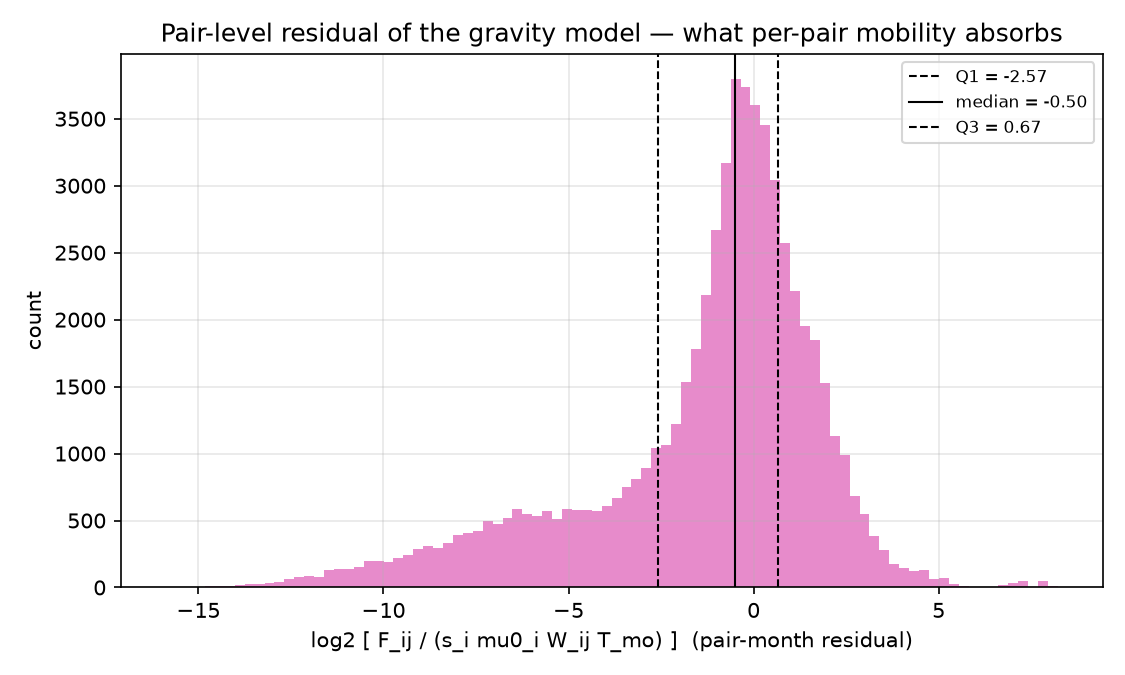

In [20]:
# the residual that pair-level mobility absorbs: log2 delta_ij(t)
delta = np.where(mask, F / np.maximum(pred, 1e-12), np.nan)
ld = np.log2(delta[mask])
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.hist(ld, bins=90, color='C6', alpha=0.85)
for q, ls, lab in ((25, '--', 'Q1'), (50, '-', 'median'), (75, '--', 'Q3')):
    ax.axvline(np.percentile(ld, q), color='k', ls=ls, lw=1,
               label=f'{lab} = {np.percentile(ld, q):.2f}')
ax.set_xlabel('log2 [ F_ij / (s_i mu0_i W_ij T_mo) ]  (pair-month residual)')
ax.set_ylabel('count')
ax.set_title('Pair-level residual of the gravity model — what per-pair mobility absorbs')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{ASSETS}/fig74_appA_pair_residuals.png'); plt.show()
show_fig(f'{ASSETS}/fig74_appA_pair_residuals.png')

## §A.10 Reconstruction summary & limitations

**Does the calibrated gravity model reproduce the BTS aviation flows?**
The numbers separate cleanly into a strong temporal half and a moderate
spatial half:

| What | Result |
|---|---|
| outbound totals (calibrated) | exact to 1e-16 (by construction) |
| kernel exponents (PPML) | $b_N \approx 1.00$, $b_d \approx 0.55$, deviance R² 0.70 |
| uniform temporal scaling | pair-correlation median **0.87**, pooled slope **1.15** vs 1.00 |
| directional shares (pooled) | **P 0.45 / S 0.58** |
| directional shares (per-state median) | **0.60** (IQR 0.49–0.78) |
| per-pair reconstruction | Pearson(raw) **0.82**; log-log **0.60**, R²(log) 0.25, median error ×2.6 |
| top-1 destination | **34.5%** |
| inbound (uncalibrated), cross-sectional | median **0.83** per month |
| inbound (uncalibrated), time series | median **0.98** (shares the COVID trend) |
| contiguous-49 robustness | P **0.56** |
| pair-level (saturated, §A.9) | R²(log) **1.000** by construction — data replay, not a model; middle ground (time-invariant pair factor) **0.91** |

**Interpretation.** Population and distance alone (plus per-state totals)
recover the *rank order* of the directional structure and almost all of the
*temporal* evolution; but the residual spatial scatter is large (median
per-pair error ×2.6), and the top-1 destination is right only a third of
the time.

**Limitations (honest).**

1. **Air ≠ all travel.** BTS T-100 covers US air carriers only. Most
   inter-state travel — and most COVID-19 seeding — is by **car**
   (FHWA VMT data, `data/fhwa_vmt_*_monthly.csv`: April-2020 air collapsed
   to ≈5% of Jan-2020, car VMT only to ≈64%). The calibrated $s_i(t)$ is an
   *aviation* mobility scale; the metapopulation uses it as a proxy for all
   human mobility (see notebook 08 §8.11 item 4). A weighted air+car
   mobility factor is the documented next step.
2. **Calibrated totals carry no information** — the experiment's power lies
   in the directional tests, which are moderate.
3. **Distance metric**: state centroid distances with a 100 km floor;
   intra-state hubs (airport pairs) would sharpen the kernel.
4. **Monthly granularity** — March 2020's aviation collapse enters only on
   the monthly grid.
5. The inbound time series ([F], median 0.98) is **not** evidence of
   predictive power: every state shares the same national COVID trend, so
   the curves are collinear.

In [21]:
pp = pred[m2]; ff = F[m2]
mm = (pp > 0) & (ff > 0)
a49, b49 = pooled_contig(Wc)
summary = pd.DataFrame({
    'metric': [
        'outbound totals (max rel err)',
        'share P pooled', 'share S pooled',
        'share P per-state median',
        'per-pair P raw', 'per-pair P log-log', 'per-pair R2 log',
        'median |log2 factor err|',
        'top-1 dest',
        'temporal pair-corr median', 'temporal pooled slope',
        'inbound cross-sectional median', 'inbound time-series median',
        'kernel exponents (PPML)',
        'contiguous-49 P',
        'pair-level R2 (saturated, §A.9)',
    ],
    'value': [
        '%.1e' % np.max(err[active] / np.maximum(out[active], 1)),
        '%.3f' % share_summary['P_pooled'][0],
        '%.3f' % share_summary['S_pooled'][0],
        '%.3f' % np.median(med_v),
        '%.3f' % pear(pp, ff),
        '%.3f' % pear(np.log(pp[mm]), np.log(ff[mm])),
        '%.3f' % r2log,
        '%.2f' % np.median(np.abs(np.log2(pp[mm] / ff[mm]))),
        '%.1f%%' % (np.mean(h1) * 100),
        '%.3f' % np.median(rs_d), '%.3f' % bfit,
        '%.3f' % np.median(r_cs), '%.3f' % np.median(rv_arr),
        'b_N=%.3f, b_d=%.3f' % (b_N, b_d),
        '%.3f' % pear(a49, b49),
        '1.000 (data replay); pair-mu0 middle ground %.2f' % r2_pair0,
    ],
})
from IPython.display import display
display(summary)
print('appendix A complete | figures fig68..fig74 -> assets/')

,metric,value
0,outbound totals (max rel err),2.6e-16
1,share P pooled,0.448
2,share S pooled,0.579
3,share P per-state median,0.597
4,per-pair P raw,0.820
5,per-pair P log-log,0.600
6,per-pair R2 log,0.247
7,median |log2 factor err|,1.38
8,top-1 dest,34.5%
9,temporal pair-corr median,0.874


appendix A complete | figures fig68..fig74 -> assets/
